# Case Study — Data Analysis and Web App

**Group number:** 19

**Members:** Enise Irem Colak, Lela Tvaliashvili

# Objective

As a part of the safety inspection by the ADAC, defected seat frame "T11" was identified. The internal investigation revealed that products with ID numbers “11-213-2131-19000” to “11-213-2131-30100” were manufactured with incorrect production parameters.

Therefore, the objective of this case study is to determine the impact of this critical production batch throughout the available production and registration data. Specifically, the analysis traces the affected T11 parts through the production hierarchy to identify the components and OEM1 vehicles in which they were installed.

The affected vehicles are then linked to the available registration and geographical information to identify the relevant records necessary for notifying the potentially affected customers.

The final result of the analysis is a cleaned, validated, analysis-ready dataset containing the complete trace from the critical T11 part to the affected vehicle and its associated registration and location information. This dataset is used as the sole data source for the accompanying web application.


# Analysis Strategy

The analysis follows a forward traceability approach including:

- Inspect the available datasets and identify the files required for the case study.
- Examine and clean T11 production parts belonging to the critical production range.
- Identify the critical T11 production batch using the manufacturer, plant, and serial-number information encoded in the specified ID range.
- Identify which component types can contain a T11 part.
- Match the critical T11 IDs to their corresponding component IDs and validate that the affected parts have been traced successfully.
- Trace the affected components to the OEM1 vehicles they are installed in.
- Enrich the affected vehicle records with vehicle-level production and defect information.
- Link the affected vehicles to registration records.
- Include the registration records with geographical information where available.
- Validate the integrated data for duplicate records, inconsistent values, and unsuccessful merges.
- Analyse and visualise the resulting affected population and key production quantities.
- Create one cleaned final dataset that contains information of all the affected parties and serves as the sole input to the web application.

## 1. Data Import

Raw data was downloaded from tubCloud and extracted into `data/raw/` at the
project root (kept out of version control — see `data/raw/README.md`). We
reach it via a relative path so the notebook keeps running if someone else
drops their own copy in the same place.

In [178]:
import csv
from pathlib import Path

import pandas as pd

RAW_DIR = Path("../../data/raw/IDA SoSe26 - Data")
assert RAW_DIR.exists(), f"Raw data not found at {RAW_DIR.resolve()} — see data/raw/README.md"

### 1.1 Listing available files

Before importing anything, we catalogue every file database
provides, grouped by category, so we can see the full scope, identify the naming patterns, file types and spot
irregularities (if any) before starting to isolate the relevant component-related tables..

In [179]:
def list_raw_files(root: Path) -> pd.DataFrame:
    """Catalogue every file under `root`, one row per file, category = subfolder name
    (or '(root)' for files sitting directly under root, outside any category folder)."""
    rows = []
    for path in sorted(root.rglob("*")):
        if path.is_file():
            category = path.parent.name if path.parent != root else "(root)"
            rows.append({
                "category": category,
                "file": path.name,
                "extension": path.suffix,
                "size_mb": round(path.stat().st_size / 1e6, 1),
            })
    return pd.DataFrame(rows)


file_catalog = list_raw_files(RAW_DIR)
print(f"{len(file_catalog)} files across {file_catalog['category'].nunique()} categories")
file_catalog.groupby(["category", "extension"]).size()

89 files across 7 categories


category        extension
(root)                        1
                .csv          1
Einzelteil      .csv         22
                .txt         16
Fahrzeug        .csv          9
Geodaten        .csv          4
                .xlsx         1
Komponente      .csv         26
                .txt          6
Logistikverzug  .csv          2
Zulassungen     .csv          1
dtype: int64

### 1.2 Manual inspection findings

The catalogue above shows several categories mixing `.txt` and `.csv` files
(e.g. `Einzelteil/`, `Komponente/`). The extension alone does not indicate information regarding the
real format, so before writing any code we opened a byte-level sample
of at least one file per category for initial manual inspection. This surfaced three issues that a standard
`pd.read_csv`  would not have been able to parse correctly:

1. **`Einzelteil_T01.txt` has no row separator at all.** The whole file is a
   single line: fields *within* a row are separated by `" | | "`, but there
   is no character marking the end of one row and the start of the next —
   the last field of row *n* is simply followed by one bare space and then
   the (quoted) row index of row *n+1*. The header also contains three
   copies of every real column, suffixed `.x`, `.y`, and unsuffixed —
   evidence of a previous merge or export operation on the source side; in the rows we
   sampled only the `.x`-suffixed columns carried real values, `.y` and the
   unsuffixed columns were all `NA`. We handle this with a dedicated parser
   (`read_glued_export` below) instead of `pd.read_csv`.
2. **`Komponente_K7.txt` looked similarly unstructured at first** (no `\n`
   anywhere in the file) but turned out to just use old-Mac-style
   `\r`-only line endings with tab as the field separator.
   `pd.read_csv(..., sep="\t", lineterminator="\r")` reads it directly —
   confirmed on the real file (306,490 rows x 9 columns).
3. **A duplicate file:** `Einzelteil_T23.csv` exists both directly under
   the data root and inside `Einzelteil/`. We byte-compared the two (`cmp`)
   and confirmed they are identical (172,075,946 bytes each) — a stray
   copy, not a distinct dataset. We treat the copy inside `Einzelteil/` as
   canonical and exclude the root-level one from import.


To identify further inconsistencies after the initial manual inspection, we inspected the relevant file from the dataset (T11) and identified a way to parse it, which is provided below in details.

1. The text files inside Einzelteil do not follow an identical structure. For instance, T01 and T11 have different formatting, namely for T11:
-  columns separated by tab, while rows are form-feed separated: \x0c, rather than a general newline character, therefore it can be read with:
*pd.read_csv(..., sep="\t", lineterminator="\x0c")*

#TODO: move this to data cleaning or somting
2. Fahrzeuge_OEM1_Typ11.csv  contains two redundant counter columns with names "" and "X1". To ensure removing this would indeed be harmless, we verify that it is indeed just a counter (df["Unnamed: 0"].head()
df["Unnamed: 0"].nunique()
len(df)) and  remove it by running df = df.drop(columns=["Unnamed: 0"]) in cell below.

As a result, we conclude that supplied dataset uses different conventions for separating the rows, therefore the single method cannot be reliably applied to read the files.  The loader in next cells detects the identified format and applies parsing accordingly.



In [180]:
def read_glued_export(path: Path, delim: str, encoding: str = "latin-1") -> pd.DataFrame:
    """Parser for exports with no row separator at all: fields within a row are
    joined by `delim`, and consecutive rows are joined by a bare space with no
    delimiter of their own (see finding #1 above). Relies on two properties that
    hold for this dataset: no real field value contains a space, and every row's
    first field is a quoted row index, with row 1 always literally '"1"'."""
    text = path.read_text(encoding=encoding)
    tokens = text.split(delim)

    unglued = []
    for tok in tokens:
        if " " in tok:
            i = tok.rindex(" ")
            unglued.append(tok[:i])
            unglued.append(tok[i + 1:])
        else:
            unglued.append(tok)

    ncols = unglued.index('"1"')
    header = [h.strip('"') for h in unglued[:ncols]]
    data = unglued[ncols:]
    data = data[: len(data) - (len(data) % ncols)]  # drop a trailing partial row, if any

    rows = [data[i : i + ncols] for i in range(0, len(data), ncols)]
    df = pd.DataFrame(rows, columns=header)
    return df.apply(lambda c: c.str.strip('"') if c.dtype == "object" else c)


def load_raw_file(path: Path) -> pd.DataFrame:
    """Reads any raw file into a DataFrame, auto-detecting which of the format
    quirks from 1.2 applies (clean CSV, form-feed-separated, \\r-only line
    endings, or fully glued/no-separator). Extend this if a new pattern turns
    up in a file we haven't sampled yet. Everything is read as latin-1 since
    the dataset is German-locale and not reliably valid UTF-8."""
    with open(path, "rb") as f:
        sample = f.read(65536)

    if b"\n" in sample:
        sample_text = sample.decode("latin-1", errors="ignore")
        try:
            sep = csv.Sniffer().sniff(sample_text, delimiters=";,\t|").delimiter
        except csv.Error:
            sep = ";"
        return pd.read_csv(path, sep=sep, encoding="latin-1")

    if b"\x0c" in sample:
        return pd.read_csv(
            path,
            sep="\t",
            lineterminator="\x0c",
            encoding="latin-1",
            na_values=["NA"],
        )

    if b"\r" in sample:
        return pd.read_csv(path, sep="\t", lineterminator="\r", encoding="latin-1")

    delim = " | | " if b" | | " in sample else "\t"
    return read_glued_export(path, delim)

### 1.3 Verifying the loader


We use *load_raw_file(path)* as adapter around several different file formats.

In [181]:
samples = {
    "Einzelteil — clean csv": RAW_DIR / "Einzelteil" / "Einzelteil_T04.csv",
    "Einzelteil — glued, no row separator": RAW_DIR / "Einzelteil" / "Einzelteil_T01.txt",
    "Komponente — \\r line endings": RAW_DIR / "Komponente" / "Komponente_K7.txt",
    "Zulassungen — clean csv": RAW_DIR / "Zulassungen" / "Zulassungen_alle_Fahrzeuge.csv",
}

for label, path in samples.items():
    df = load_raw_file(path)
    print(f"{label}: {df.shape}")
    display(df.head(3))

Einzelteil — clean csv: (1192630, 10)


,Unnamed: 0,X1,ID_T04,Herstellernummer,Werksnummer,Fehlerhaft,Fehlerhaft_Datum,Fehlerhaft_Fahrleistung,Produktionsdatum_Origin_01011970,origin
0,1,1,4-204-2043-113,204,2043,0,NaN,0,14190,01-01-1970
1,2,2,4-202-2023-18,202,2023,0,NaN,0,14190,01-01-1970
2,3,3,4-204-2043-98,204,2043,0,NaN,0,14190,01-01-1970


Einzelteil — glued, no row separator: (3349745, 22)


,X1,ID_T01.x,Produktionsdatum.x,Herstellernummer.x,Werksnummer.x,Fehlerhaft.x,Fehlerhaft_Datum.x,Fehlerhaft_Fahrleistung.x,ID_T01.y,Produktionsdatum.y,...,Fehlerhaft.y,Fehlerhaft_Datum.y,Fehlerhaft_Fahrleistung.y,ID_T01,Produktionsdatum,Herstellernummer,Werksnummer,Fehlerhaft,Fehlerhaft_Datum,Fehlerhaft_Fahrleistung
0,1,660,1-201-2011-247,2008-11-07,201,2011,0,NA,0,NA,...,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
1,NA,2,661,1-201-2011-429,2008-11-07,201,2011,0,NA,0,...,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA
2,NA,NA,3,662,1-201-2011-363,2008-11-07,201,2011,1,2009-09-30,...,NA,NA,NA,NA,NA,NA,NA,NA,NA,NA


Komponente — \r line endings: (306490, 9)


,X1,ID_Karosserie,Herstellernummer,Werksnummer,Fehlerhaft,Fehlerhaft_Datum,Fehlerhaft_Fahrleistung,Produktionsdatum_Origin_01011970,origin
1,1,K7-114-1142-1,114,1142,0,NaN,0,14195,01-01-1970
2,2,K7-114-1142-2,114,1142,0,NaN,0,14195,01-01-1970
3,3,K7-114-1142-5,114,1142,0,NaN,0,14196,01-01-1970


Zulassungen — clean csv: (3204104, 4)


,Unnamed: 0,IDNummer,Gemeinden,Zulassung
0,408097,11-1-11-1,DRESDEN,2009-01-01
1,408098,11-1-11-2,DRESDEN,2009-01-01
2,1,12-1-12-1,LEIPZIG,2009-01-01


# 2. EDA

Since T11 is the starting point of the traceability analysis, we start by inspecting Einzelteil_T11.txt in the Einzelteil folder. Unrelated individual-part datasets are therefore not imported at this stage.

Before data transformation anything, we conduct Exploratory Data Analysis to identify types, missing values, defect distribution, etc.

In [182]:
t11_path = RAW_DIR/"Einzelteil"/"Einzelteil_T11.txt"

t11 = load_raw_file(t11_path)

print(f"Rows: {t11.shape[0]:,}")
print(f"Columns: {t11.shape[1]}")

#display the first and last 5 rows for getting the overview of entries.
print(t11.head())
print(t11.tail())

#brief summary of data
t11.info()

Rows: 2,385,260
Columns: 9
   X1           ID_T11  Herstellernummer  Werksnummer  Fehlerhaft  \
1   1  11-215-2154-102               215         2154           0   
2   2  11-212-2121-124               212         2121           0   
3   3  11-213-2131-128               213         2131           0   
4   4    11-212-2121-4               212         2121           0   
5   5   11-213-2131-70               213         2131           0   

  Fehlerhaft_Datum  Fehlerhaft_Fahrleistung  Produktionsdatum_Origin_01011970  \
1              NaN                      0.0                             14190   
2              NaN                      0.0                             14190   
3              NaN                      0.0                             14190   
4              NaN                      0.0                             14190   
5              NaN                      0.0                             14190   

       origin  
1  01-01-1970  
2  01-01-1970  
3  01-01-1970  
4  01-0

After initial inspection, we can see that out of  2,385,260 entires, 2147106, i.e. 90% of entries in do not contain a value in column Fehlerhaft_Datum. This is not a data quality error automatically, so we cross-check with Fahlerhaft to determine if these missing records correspond to entries for which no defect was recorded.

In [183]:
missing_values = (
    t11.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("missing_values")
)

missing_values["percentage"] = (
    missing_values["missing_values"] / len(t11) * 100
).round(2)

display(missing_values)

,missing_values,percentage
Fehlerhaft_Datum,2147106,90.02
X1,0,0.00
ID_T11,0,0.00
Herstellernummer,0,0.00
Werksnummer,0,0.00
Fehlerhaft,0,0.00
Fehlerhaft_Fahrleistung,0,0.00
Produktionsdatum_Origin_01011970,0,0.00
origin,0,0.00


A cross-check with the Fehlerhaft indicator shows that these missing dates correspond to parts for which no defect was recorded, while defective parts contain a defect date.

In [184]:
pd.crosstab(
    t11["Fehlerhaft"],
    t11["Fehlerhaft_Datum"].isna(),
    margins=True
)

#Fehlerhaft = 0 → mileage = 0
#Fehlerhaft = 1 → mileage > 0

Fehlerhaft_Datum,False,True,All
Fehlerhaft,,,
0,0,2147106,2147106
1,238154,0,238154
All,238154,2147106,2385260


To check if dataset contains duplicated entires, we also run the following cell. Duplicate IDs could create ambiguous component mappings or duplicate records during later joins. Therefore, it is important to ensure they are caught if they exist in the data records.

In [185]:
print(f"Duplicated rows: {t11.duplicated().sum():,}")
print(
    "Duplicate T11 IDs:",
    t11["ID_T11"].duplicated().sum()
)

Duplicated rows: 0
Duplicate T11 IDs: 0


After checking duplicates, we check how many distinct values we have in each rows for *Herstellernummer*, **Werksnummer* and *Fehlerhaft*

In [186]:
display(t11["Herstellernummer"].value_counts(dropna=False)) #manufacturers 213, 212 and 215 produced T11
display(t11["Werksnummer"].value_counts(dropna=False))
display(t11["Fehlerhaft"].value_counts(dropna=False))


Herstellernummer
213    1192630
212     715578
215     477052
Name: count, dtype: int64

Werksnummer
2131    1192630
2121     715578
2154     477052
Name: count, dtype: int64

Fehlerhaft
0    2147106
1     238154
Name: count, dtype: int64

We pay particular attention to the variables Fehlerhaft, Fehlerhaft_Datum, and Fehlerhaft_Fahrleistung.Fehlerhaft indicates whether a defect was recorded for the part, Fehlerhaft_Datum records the corresponding defect date, and Fehlerhaft_Fahrleistung represents the mileage at which the defect was recorded.

To further assess the internal consistency of the defect-related variables, we compare the availability and min anx max values of defect dates and defect mileage between records with and without a recorded defect.

In [187]:
print(
    t11.groupby("Fehlerhaft")[
        ["Fehlerhaft_Datum", "Fehlerhaft_Fahrleistung"]
    ].agg(["count", "min", "max"])
)

           Fehlerhaft_Datum                         Fehlerhaft_Fahrleistung  \
                      count         min         max                   count   
Fehlerhaft                                                                    
0                         0         NaN         NaN                 2147106   
1                    238154  2009-11-03  2017-11-01                  238154   

                                        
                     min           max  
Fehlerhaft                              
0               0.000000      0.000000  
1           23484.624658  34196.909589  


T11 export has an unusual extra row-index value, and X1 also appears to be a row counter. First we verify this assumption, and then we drop the column containing the duplicated information

In [188]:
print(t11.index[:10])
print(t11["X1"].head(10).tolist())

print("Rows:", len(t11))
print("Unique X1:", t11["X1"].nunique())
print("Duplicate X1:", t11["X1"].duplicated().sum())

Index([1, 2, 3, 4, 5, 6, 7, 8, 9, 10], dtype='int64')
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Rows: 2385260
Unique X1: 2385260
Duplicate X1: 0


X1 was verified to contain a unique sequential number for every observation (2,385,260 unique values across 2,385,260 rows), matching the source row index. It therefore represents an export-generated row counter rather than a production attribute and is removed from the analysis. (this is data cleaning step)

In [189]:
t11 = t11.reset_index(drop=True) #ensures that dataframe behaves like ordinary pandas row index
t11 = t11.drop(columns=["X1"])

We can conclude that X1 is an export-generated row counter with no production meaning.

Important column for the objectie is Fehlerhaft_Datum. To correctly analyze the values, we need to convert them to datetime type, as When pandas reads a CSV/text file, these may initially be stored as generic strings/objects rather than actual dates. This could help us further inspect earliest and latest dates of the defect by using .min() and .max() methods if necessary or extract month, year or other relevant information that is not as straightforward using strings.

"coerce" ensures that in case pandas encounters something that cannot be interpreted as a valid date, will get converted to NaT (Not a Time). The motivation for using this is presence of NA for non-defective records.

overview: : inspect raw type → convert to appropriate datetime type → verify that no valid non-missing records were lost during conversion.

In [190]:
t11["Fehlerhaft_Datum"] = pd.to_datetime(
    t11["Fehlerhaft_Datum"],
    errors="coerce"
)

#converts the column into a real pandas datetime type.

# Overview of production-date encoding:

Production date is stored as number of days since 01-01-1970, i.e.
 origin = 1970-01-01 + 14190 days = actual production date.

we will need to inspect the production date for the following reasons:
- checking when the critical batch was produced,
- detecting impossible dates,
- potentially showing the affected production period in your final analysis.

In [191]:
print(
    t11[
        ["Produktionsdatum_Origin_01011970", "origin"]
    ].head()
)

   Produktionsdatum_Origin_01011970      origin
0                             14190  01-01-1970
1                             14190  01-01-1970
2                             14190  01-01-1970
3                             14190  01-01-1970
4                             14190  01-01-1970


Check for ensuring that conversion did not introduce any accidental errors

In [192]:
original_dates = t11["Fehlerhaft_Datum"].copy()
#convert
parsed_dates = pd.to_datetime(
    original_dates,
    format="%Y-%m-%d",
    errors="coerce"
)

failed_conversion = (
    original_dates.notna()
    & parsed_dates.isna()
)

print("Non-missing dates before:", original_dates.notna().sum())
print("Dates that failed conversion:", failed_conversion.sum())

t11["Fehlerhaft_Datum"] = parsed_dates

Non-missing dates before: 238154
Dates that failed conversion: 0


No non-missing defect dates were lost during conversion, confirming that the original date values follow the expected format.

To identify whih Manufacturing companies and Production sites produced T11, and how many T11 parts came from each, we group the records that have the same manufacturer and manufacturing plant number (Werksnummer). This shows which combinations of these produced T11 parts, along with the quantities of production (in column "count" below).


In [193]:
manufacturer_and_plant_grouped = t11.groupby(
        ["Herstellernummer", "Werksnummer"]
    ).size().reset_index(name="count")

print(manufacturer_and_plant_grouped)

   Herstellernummer  Werksnummer    count
0               212         2121   715578
1               213         2131  1192630
2               215         2154   477052


From the criticla ID (*11-213-2131-19000*) itself, we know that:

- 11   = T11
- 213  = manufacturer
- 2131 = manufacturing plant
- 19000 = serial number

T11 was produced by multiple manufacturers. For the case study, however, manufacturer 213 and plant 2131 are of particular importance because the specified critical ID range 11-213-2131-19000 to 11-213-2131-30100 originates from this manufacturer–plant combination.


Therefore, the critical production batch specifically means:
T11 parts manufactured by manufacturer 213 at plant 2131 whose serial number is between 19000 and 30100.

# next steps:

1. clean T11
        ↓
2. extract serial number from ID_T11
        ↓
3. filter manufacturer 213
        ↓
4. filter plant 2131
        ↓
5. filter only serial 19000–30100 and store into critical_t11

And after critical_t11 exists, we can start exploring which components contain one of these critical T11 IDs.

11-213-2131-19000
        ↓
11-213-2131-30100

before doing that, we need to identify the structure of ID column to ensure looking for the values above is consistent with the format



In [194]:
t11_clean = t11.copy()
print(t11_clean.shape)
print(t11_clean.columns.tolist())

(2385260, 8)
['ID_T11', 'Herstellernummer', 'Werksnummer', 'Fehlerhaft', 'Fehlerhaft_Datum', 'Fehlerhaft_Fahrleistung', 'Produktionsdatum_Origin_01011970', 'origin']


Before extracting the sequential number, the ID_T11 structure is checked for consistency to ensure the expected 4-hyphen-separated segments exist and begins with T11 designation.

In [195]:
id_segment_counts = (
    t11_clean["ID_T11"]
    .str.count("-")
    .add(1)
    .value_counts()
)

display(id_segment_counts)

print(
    "IDs with unexpected part designation:",
    (~t11_clean["ID_T11"].str.startswith("11-")).sum()
)

ID_T11
4    2385260
Name: count, dtype: int64

IDs with unexpected part designation: 0


In [196]:
#extract the serial number from ID_T11.
t11_clean["serial_number"] = pd.to_numeric(
    t11_clean["ID_T11"].str.rsplit("-", n=1).str[-1],
    errors="coerce"
) #creates serial number by taking serial_number = 19000 from 11-213-2131-19000

# Instead of comparing entire strings, we can compare the new derived field: serial_number
print(t11_clean[["ID_T11", "serial_number"]].head(10))

print(
    "Failed serial number extractions:",
    t11_clean["serial_number"].isna().sum()
)

            ID_T11  serial_number
0  11-215-2154-102            102
1  11-212-2121-124            124
2  11-213-2131-128            128
3    11-212-2121-4              4
4   11-213-2131-70             70
5  11-212-2121-133            133
6  11-213-2131-229            229
7  11-212-2121-163            163
8  11-213-2131-396            396
9  11-212-2121-188            188
Failed serial number extractions: 0


Now that we validated the serial number extraction, we can create the critical batch with serial numbers from 19000 through 20100 by filtering manufacturer 213, plant 2131 and serial number range.

In [197]:
critical_t11 = t11_clean[
    (t11_clean["Herstellernummer"].astype(str) == "213")
    & (t11_clean["Werksnummer"].astype(str) == "2131")
    & (t11_clean["serial_number"].between(19000, 30100))
].copy()

print(f"Critical T11 records: {len(critical_t11):,}")

print(
    "Serial range:",
    critical_t11["serial_number"].min(),
    "to",
    critical_t11["serial_number"].max()
)

print(
    "Manufacturers:",
    critical_t11["Herstellernummer"].unique()
)

print(
    "Plants:",
    critical_t11["Werksnummer"].unique()
)

print(
    "Duplicate critical IDs:",
    critical_t11["ID_T11"].duplicated().sum()
)

print(critical_t11.head()) #30100 - 19000 + 1 = 11,101

expected_serials = set(range(19000, 30101))

actual_serials = set(
    critical_t11["serial_number"].dropna().astype(int)
)

missing_serials = expected_serials - actual_serials

print("Expected possible serials:", len(expected_serials))
print("Present serials:", len(actual_serials))
print("Missing serials:", len(missing_serials))

display(
    critical_t11["Fehlerhaft"]
    .value_counts(dropna=False)
    .rename("count")
)

Critical T11 records: 11,101
Serial range: 19000 to 30100
Manufacturers: [213]
Plants: [2131]
Duplicate critical IDs: 0
                  ID_T11  Herstellernummer  Werksnummer  Fehlerhaft  \
35823  11-213-2131-19101               213         2131           1   
35860  11-213-2131-19078               213         2131           0   
35953  11-213-2131-19157               213         2131           0   
35966  11-213-2131-19002               213         2131           0   
36018  11-213-2131-19229               213         2131           0   

      Fehlerhaft_Datum  Fehlerhaft_Fahrleistung  \
35823       2009-12-19                  30076.8   
35860              NaT                      0.0   
35953              NaT                      0.0   
35966              NaT                      0.0   
36018              NaT                      0.0   

       Produktionsdatum_Origin_01011970      origin  serial_number  
35823                             14236  01-01-1970          19101  
35860   

Fehlerhaft
0    9923
1    1178
Name: count, dtype: int64

This confirms that the critical production batch has been isolated completely according to the case-study specification. Of the 11,101 parts in the critical production batch, 1,178 already have a recorded defect (Fehlerhaft = 1), while 9,923 do not. However, the critical population is defined by the known production-parameter error and specified ID range, not by the historical Fehlerhaft flag. Therefore, all 11,101 parts must be traced through the production hierarchy regardless of whether a defect has already been recorded. The following visualization distinguishes the known critical production population from historically recorded defect.

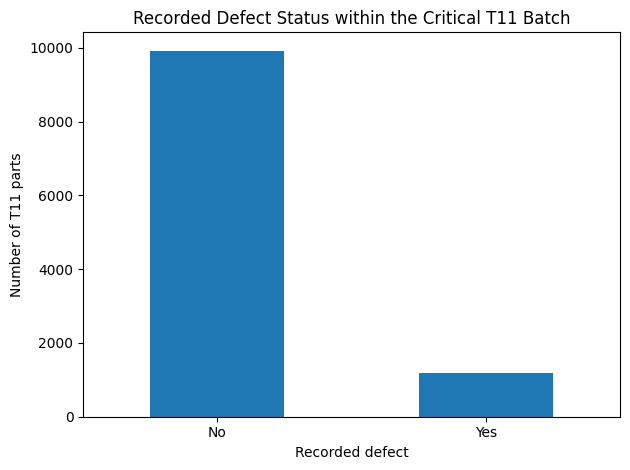

In [198]:
import matplotlib.pyplot as plt

critical_defect_counts = (
    critical_t11["Fehlerhaft"]
    .value_counts()
    .sort_index()
)

ax = critical_defect_counts.plot(kind="bar")

ax.set_title("Recorded Defect Status within the Critical T11 Batch")
ax.set_xlabel("Recorded defect")
ax.set_ylabel("Number of T11 parts")
ax.set_xticklabels(["No", "Yes"], rotation=0)

plt.tight_layout()
plt.show()

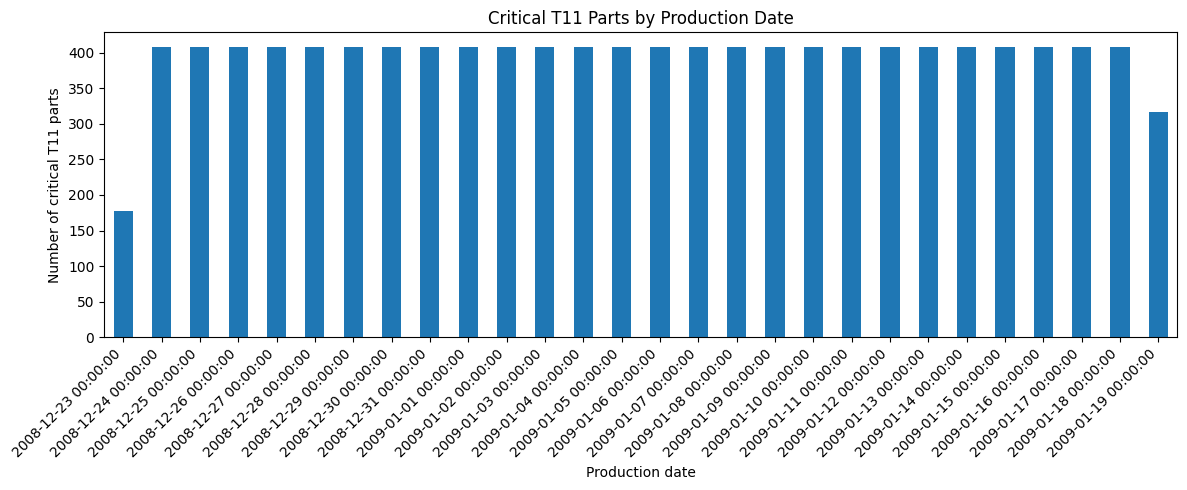

In [199]:
ax = critical_production_daily.plot(
    kind="bar",
    figsize=(12, 5)
)

ax.set_title("Critical T11 Parts by Production Date")
ax.set_xlabel("Production date")
ax.set_ylabel("Number of critical T11 parts")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

The 11,101 critical T11 parts were produced over the period shown above. Production quantities are relatively stable across the central part of the affected period, while fewer critical parts occur on the first and last production dates. This is consistent with the critical population being defined by a sequential ID interval rather than by complete production days.

# 3. Trace Critical T11 Parts to Components

The next step is to determine which higher-level components contain the T11 parts.

- We inspect the Bestandteile_Komponente_*  files and trace T11 IDs through production hierarchy. These files describe individual parts that are used to assemble a particular component type.
- Once the relevant component types are identified, the critical `ID_T11` values
are matched against the `ID_T11` column in those parts lists. A match means that
a specific critical T11 part was installed in the corresponding component ID.

In [200]:
component_path = RAW_DIR/"Komponente"

component_bom_files = sorted(
    component_path.glob("Bestandteile_Komponente_*")
)

print( "Component parts-list files inspected:",
    len(component_bom_files)
)
for path in component_bom_files:
    print(path.name)

Component parts-list files inspected: 16
Bestandteile_Komponente_K1BE1.csv
Bestandteile_Komponente_K1BE2.csv
Bestandteile_Komponente_K1DI1.csv
Bestandteile_Komponente_K1DI2.csv
Bestandteile_Komponente_K2LE1.csv
Bestandteile_Komponente_K2LE2.csv
Bestandteile_Komponente_K2ST1.csv
Bestandteile_Komponente_K2ST2.csv
Bestandteile_Komponente_K3AG1.csv
Bestandteile_Komponente_K3AG2.csv
Bestandteile_Komponente_K3SG1.csv
Bestandteile_Komponente_K3SG2.csv
Bestandteile_Komponente_K4.csv
Bestandteile_Komponente_K5.csv
Bestandteile_Komponente_K6.csv
Bestandteile_Komponente_K7.csv


In [201]:
for path in component_bom_files:
    df_header = pd.read_csv(
        path,
        nrows=0,
        sep=None,
        engine="python"
    )

    print(f"\n{path.name}")
    print(df_header.columns.tolist())

    if "ID_T11" in df_header.columns:
        print(f"  -> T11 found in {path.name}")


Bestandteile_Komponente_K1BE1.csv
['Unnamed: 0', 'ID_T1', 'ID_T2', 'ID_T3', 'ID_T4', 'ID_K1BE1']

Bestandteile_Komponente_K1BE2.csv
['Unnamed: 0', 'ID_T1', 'ID_T2', 'ID_T7', 'ID_T8', 'ID_K1BE2']

Bestandteile_Komponente_K1DI1.csv
['Unnamed: 0', 'ID_T1', 'ID_T2', 'ID_T5', 'ID_T6', 'ID_K1DI1']

Bestandteile_Komponente_K1DI2.csv
['Unnamed: 0', 'ID_T1', 'ID_T2', 'ID_T9', 'ID_T10', 'ID_K1DI2']

Bestandteile_Komponente_K2LE1.csv
['Unnamed: 0', 'ID_T11', 'ID_T14', 'ID_T15', 'ID_K2LE1']
  -> T11 found in Bestandteile_Komponente_K2LE1.csv

Bestandteile_Komponente_K2LE2.csv
['Unnamed: 0', 'ID_T16', 'ID_T19', 'ID_T20', 'ID_K2LE2']

Bestandteile_Komponente_K2ST1.csv
['X1', 'X', 'ID_T11', 'ID_T12', 'ID_T13', 'ID_K2ST1']
  -> T11 found in Bestandteile_Komponente_K2ST1.csv

Bestandteile_Komponente_K2ST2.csv
['Unnamed: 0', 'ID_T16', 'ID_T17', 'ID_T18', 'ID_K2ST2']

Bestandteile_Komponente_K3AG1.csv
['X1', 'ID_T21', 'ID_T24', 'ID_T25', 'ID_K3AG1']

Bestandteile_Komponente_K3AG2.csv
['X1', 'ID_T21', 'I

The schema inspection shows that `ID_T11` occurs only in:

- `Bestandteile_Komponente_K2LE1.csv`
- `Bestandteile_Komponente_K2ST1.csv`

Therefore, T11 can be installed in component types K2LE1 and K2ST1.

In [202]:
k2le1_bom = load_raw_file(
    RAW_DIR / "Komponente" / "Bestandteile_Komponente_K2LE1.csv"
)

k2st1_bom = load_raw_file(
    RAW_DIR / "Komponente" / "Bestandteile_Komponente_K2ST1.csv"
)

print("K2LE1:", k2le1_bom.shape)
display(k2le1_bom.head())

print("K2ST1:", k2st1_bom.shape)
display(k2st1_bom.head())

K2LE1: (477052, 5)


,Unnamed: 0,ID_T11,ID_T14,ID_T15,ID_K2LE1
0,1,11-215-2154-70,14-214-2142-8,15-209-2093-12,K2LE1-109-1091-1
1,2,11-215-2154-102,14-214-2142-11,15-209-2093-20,K2LE1-109-1091-2
2,3,11-212-2121-7,14-213-2132-1,15-210-2101-2,K2LE1-109-1091-3
3,4,11-212-2121-61,14-213-2132-5,15-210-2101-21,K2LE1-109-1091-4
4,5,11-212-2121-95,14-213-2132-6,15-210-2101-24,K2LE1-109-1091-5


K2ST1: (1908208, 6)


,X1,X,ID_T11,ID_T12,ID_T13,ID_K2ST1
0,1,1,11-213-2131-128,12-212-2121-15,13-209-2091-25,K2ST1-109-1092-1
1,2,2,11-213-2131-134,12-212-2121-28,13-209-2092-7,K2ST1-109-1092-2
2,3,3,11-212-2121-107,12-212-2121-73,13-209-2092-69,K2ST1-109-1092-3
3,4,4,11-213-2131-182,12-212-2122-41,13-209-2092-77,K2ST1-109-1092-4
4,5,5,11-212-2121-124,12-212-2122-71,13-209-2092-86,K2ST1-109-1092-5


In [203]:
for name, df, component_col in [
    ("K2LE1", k2le1_bom, "ID_K2LE1"),
    ("K2ST1", k2st1_bom, "ID_K2ST1"),
]:
    print(f"\n{name}")
    print("Rows:", len(df))
    print("Missing T11 IDs:", df["ID_T11"].isna().sum())
    print(
        "Missing component IDs:",
        df[component_col].isna().sum()
    )
    print(
        "Duplicate T11 IDs:",
        df["ID_T11"].duplicated().sum()
    )
    print(
        "Duplicate component IDs:",
        df[component_col].duplicated().sum()
    )


K2LE1
Rows: 477052
Missing T11 IDs: 0
Missing component IDs: 0
Duplicate T11 IDs: 0
Duplicate component IDs: 0

K2ST1
Rows: 1908208
Missing T11 IDs: 0
Missing component IDs: 0
Duplicate T11 IDs: 0
Duplicate component IDs: 0


Before using these files for traceability, the relevant join fields are checked
for missing and duplicate values.

After that, The set of 11,101 critical T11 IDs is  compared with the `ID_T11` field in
both relevant component parts lists. Only rows containing one of these critical
IDs are retained. The `ID_K2LE1` and `ID_K2ST1` value identifies the
specific higher-level component containing that critical T11 part.

In [204]:
k2le1_trace = k2le1_bom[
    ["ID_T11", "ID_K2LE1"]
].copy()

k2st1_trace = k2st1_bom[
    ["ID_T11", "ID_K2ST1"]
].copy()

critical_ids = set(critical_t11["ID_T11"])

affected_k2le1 = k2le1_trace[
    k2le1_trace["ID_T11"].isin(critical_ids)
].copy()

affected_k2st1 = k2st1_trace[
    k2st1_trace["ID_T11"].isin(critical_ids)
].copy()

print("Affected K2LE1 rows:", len(affected_k2le1))
print("Affected K2LE1 components:", affected_k2le1["ID_K2LE1"].nunique())

print("Affected K2ST1 rows:", len(affected_k2st1))
print("Affected K2ST1 components:", affected_k2st1["ID_K2ST1"].nunique())

display(affected_k2le1.head())
display(affected_k2st1.head())

Affected K2LE1 rows: 2201
Affected K2LE1 components: 2201
Affected K2ST1 rows: 8900
Affected K2ST1 components: 8900


,ID_T11,ID_K2LE1
7545,11-213-2131-19061,K2LE1-109-1091-7546
7546,11-213-2131-19134,K2LE1-109-1091-7547
7547,11-213-2131-19141,K2LE1-109-1091-7548
7551,11-213-2131-19447,K2LE1-109-1091-7552
7552,11-213-2131-19466,K2LE1-109-1091-7553


,ID_T11,ID_K2ST1
28661,11-213-2131-19005,K2ST1-109-1092-28662
28748,11-213-2131-19171,K2ST1-109-1092-28749
28756,11-213-2131-19059,K2ST1-109-1092-28757
28838,11-213-2131-19039,K2ST1-109-1092-28839
28931,11-213-2131-19043,K2ST1-109-1092-28932


Because the component IDs have different column names, we standardize them first to `component_id`. A new
`component_type` variable preserves whether the original component belongs to
K2LE1 or K2ST1.

In [205]:
affected_k2le1 = affected_k2le1.rename(
    columns={"ID_K2LE1": "component_id"}
)
affected_k2le1["component_type"] = "K2LE1"

affected_k2st1 = affected_k2st1.rename(
    columns={"ID_K2ST1": "component_id"}
)
affected_k2st1["component_type"] = "K2ST1"

#and then combine them

affected_components = pd.concat(
    [
        affected_k2le1[["ID_T11", "component_id", "component_type"]],
        affected_k2st1[["ID_T11", "component_id", "component_type"]],
    ],
    ignore_index=True
)

print("Affected component relationships:", len(affected_components))
print("Unique critical T11 IDs matched:", affected_components["ID_T11"].nunique())
print("Unique affected components:", affected_components["component_id"].nunique())

display(affected_components.head())

Affected component relationships: 11101
Unique critical T11 IDs matched: 11101
Unique affected components: 11101


,ID_T11,component_id,component_type
0,11-213-2131-19061,K2LE1-109-1091-7546,K2LE1
1,11-213-2131-19134,K2LE1-109-1091-7547,K2LE1
2,11-213-2131-19141,K2LE1-109-1091-7548,K2LE1
3,11-213-2131-19447,K2LE1-109-1091-7552,K2LE1
4,11-213-2131-19466,K2LE1-109-1091-7553,K2LE1


In [206]:
print( "Duplicate T11-component relationships:",
    affected_components[
        ["ID_T11", "component_id"]
    ].duplicated().sum()
)

print( "T11 IDs mapped to multiple components:",
    affected_components.groupby("ID_T11")["component_id"]
    .nunique()
    .gt(1)
    .sum()
)

Duplicate T11-component relationships: 0
T11 IDs mapped to multiple components: 0


The affected population is concentrated in K2ST1 components: 8,900 of the
11,101 critical T11 parts were installed in K2ST1 components, while 2,201 were
installed in K2LE1 components. Both component types must therefore be included
in the subsequent vehicle trace.

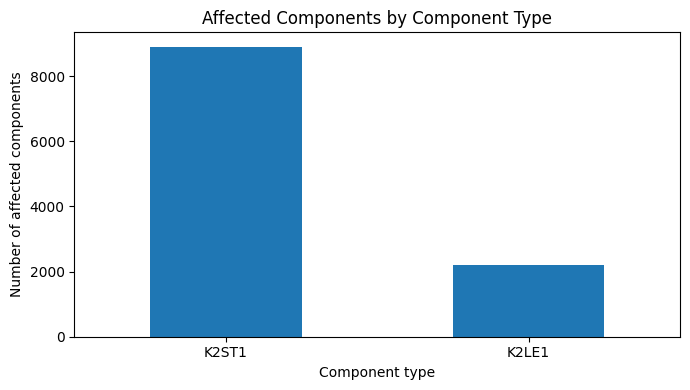

In [207]:
component_type_counts = (
    affected_components["component_type"]
    .value_counts()
)

ax = component_type_counts.plot(
    kind="bar",
    figsize=(7, 4)
)

ax.set_title("Affected Components by Component Type")
ax.set_xlabel("Component type")
ax.set_ylabel("Number of affected components")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

We finally check whether every critical T11 was actually found in one of these component parts lists:

In [208]:
matched_t11_ids = set(affected_components["ID_T11"])

unmatched_t11_ids = critical_ids - matched_t11_ids

print("Critical T11 IDs:", len(critical_ids))
print("Matched to a component:", len(matched_t11_ids))
print("Not matched to a component:", len(unmatched_t11_ids))

Critical T11 IDs: 11101
Matched to a component: 11101
Not matched to a component: 0


All 11,101 T11 parts belonging to the critical production batch were successfully
matched to a higher-level component: 2,201 installed in K2LE1 components and
8,900 in K2ST1 components, with no critical T11 IDs left unmatched. The number
of unique T11 IDs, component relationships, and unique component IDs is
identical (11,101), indicating a one-to-one T11-to-component relationship in
the observed parts-list data.

# 4: Identify Affected Vehicles based on affected componenets

Previous cells identified the relevant componens we need to files that contain information regarding which components are installed in OEM1 vehicles  :
- Bestandteile_Fahrzeuge_OEM1_Typ11.csv
- Bestandteile_Fahrzeuge_OEM1_Typ12.csv

Now we want to check which vehicles contain K2LE1 and K2ST1 components.

In [209]:
vehicle_files = [
    RAW_DIR/"Fahrzeug"/"Bestandteile_Fahrzeuge_OEM1_Typ11.csv",
    RAW_DIR/"Fahrzeug"/"Bestandteile_Fahrzeuge_OEM1_Typ12.csv",
]

for path in vehicle_files:
    header = pd.read_csv(path, nrows=0,  sep=None, engine="python")
    print(f"\n{path.name}")
    print(header.columns.tolist())


Bestandteile_Fahrzeuge_OEM1_Typ11.csv
['Unnamed: 0', 'ID_Karosserie', 'ID_Schaltung', 'ID_Sitze', 'ID_Motor', 'ID_Fahrzeug']

Bestandteile_Fahrzeuge_OEM1_Typ12.csv
['Unnamed: 0', 'ID_Karosserie', 'ID_Schaltung', 'ID_Sitze', 'ID_Motor', 'ID_Fahrzeug']


Since T11 is a seat-related part, we look into ID_Sitze as this is where the seat-related components would appear.

Hypothesis:
component_id
(K2LE1 / K2ST1)
       ↓
ID_Sitze
       ↓
ID_Fahrzeug

To verify this assumption, we preview a few samples.

In [210]:
for path in vehicle_files:
    sample = pd.read_csv(
        path,
        nrows=10,
        sep=None,
        engine="python"
    )

    print(f"\n{path.name}")
    display(sample[["ID_Sitze", "ID_Fahrzeug"]])


Bestandteile_Fahrzeuge_OEM1_Typ11.csv


,ID_Sitze,ID_Fahrzeug
0,K2LE1-109-1091-2,11-1-11-1
1,K2ST1-109-1092-5,11-1-11-2
2,K2ST1-109-1092-57,11-1-11-3
3,K2ST1-109-1092-91,11-1-11-4
4,K2ST1-109-1092-4,11-1-11-5
5,K2ST1-109-1092-2,11-1-11-6
6,K2ST1-109-1092-81,11-1-11-7
7,K2ST1-109-1092-74,11-1-11-8
8,K2LE1-109-1091-5,11-1-11-9
9,K2ST1-109-1092-148,11-1-11-10



Bestandteile_Fahrzeuge_OEM1_Typ12.csv


,ID_Sitze,ID_Fahrzeug
0,K2ST1-109-1092-1,12-1-12-1
1,K2ST1-109-1092-16,12-1-12-2
2,K2ST1-109-1092-21,12-1-12-3
3,K2ST1-109-1092-70,12-1-12-4
4,K2ST1-109-1092-78,12-1-12-5
5,K2ST1-109-1092-82,12-1-12-6
6,K2ST1-109-1092-167,12-1-12-7
7,K2ST1-109-1092-183,12-1-12-8
8,K2ST1-109-1092-187,12-1-12-9
9,K2LE1-109-1091-12,12-1-12-10


The results above confirm that ID_Sitze is indeed the column where the affected components appear. After this, we load the relevant columns.

In [211]:
affected_seat_ids = set(
    affected_components["component_id"]
)

print("Affected seat component IDs:", len(affected_seat_ids))

Affected seat component IDs: 11101


The component trace contains 11,101 unique affected seat-component IDs.
These IDs are used to search the `ID_Sitze` field of the OEM1 vehicle
parts lists.


In [212]:
vehicle_boms = []

for path in vehicle_files:
    df = pd.read_csv(
        path,
        sep=None,
        engine="python",
        usecols=["ID_Sitze", "ID_Fahrzeug"]
    )

    if "Typ11" in path.name:
        df["vehicle_type"] = "Typ11"
    elif "Typ12" in path.name:
        df["vehicle_type"] = "Typ12"

    vehicle_boms.append(df)

vehicle_bom = pd.concat(
    vehicle_boms,
    ignore_index=True
)

print(vehicle_bom.shape)
display(vehicle_bom.head())

(2385260, 3)


,ID_Sitze,ID_Fahrzeug,vehicle_type
0,K2LE1-109-1091-2,11-1-11-1,Typ11
1,K2ST1-109-1092-5,11-1-11-2,Typ11
2,K2ST1-109-1092-57,11-1-11-3,Typ11
3,K2ST1-109-1092-91,11-1-11-4,Typ11
4,K2ST1-109-1092-4,11-1-11-5,Typ11


In [213]:
print("Vehicle BOM rows:", len(vehicle_bom))

print(
    "Missing seat component IDs:",
    vehicle_bom["ID_Sitze"].isna().sum()
)

print(
    "Missing vehicle IDs:",
    vehicle_bom["ID_Fahrzeug"].isna().sum()
)

print(
    "Duplicate vehicle IDs:",
    vehicle_bom["ID_Fahrzeug"].duplicated().sum()
)

print(
    "Duplicate seat component IDs:",
    vehicle_bom["ID_Sitze"].duplicated().sum()
)

Vehicle BOM rows: 2385260
Missing seat component IDs: 0
Missing vehicle IDs: 0
Duplicate vehicle IDs: 0
Duplicate seat component IDs: 0


The vehicle parts lists are filtered to retain records whose ID_Sitze belongs to the set of affected component IDs.”

In [214]:
affected_vehicle_rows = vehicle_bom[
    vehicle_bom["ID_Sitze"].isin(affected_seat_ids)
].copy()

print("Matched component-to-vehicle rows:", len(affected_vehicle_rows))
print("Unique affected vehicles:",
      affected_vehicle_rows["ID_Fahrzeug"].nunique())

display(affected_vehicle_rows.head())

Matched component-to-vehicle rows: 11101
Unique affected vehicles: 11101


,ID_Sitze,ID_Fahrzeug,vehicle_type
29621,K2ST1-109-1092-29921,11-1-11-19025,Typ11
29658,K2ST1-109-1092-29668,11-1-11-19062,Typ11
29751,K2ST1-109-1092-29765,11-1-12-10603,Typ11
29764,K2ST1-109-1092-29223,11-1-12-10616,Typ11
29816,K2ST1-109-1092-29929,11-1-12-10668,Typ11


also we want to preserve the enitre trace from T11 to vehicle, so we need to merge the results back to affected_components


In [215]:
affected_vehicles = affected_components.merge(
    affected_vehicle_rows,
    left_on="component_id",
    right_on="ID_Sitze",
    how="left",
    validate="one_to_one",
    indicator=True
)

display(affected_vehicles.head())

print("Trace rows:", len(affected_vehicles))
print("Unique T11 IDs:", affected_vehicles["ID_T11"].nunique())
print("Unique components:", affected_vehicles["component_id"].nunique())
print("Unique vehicles:", affected_vehicles["ID_Fahrzeug"].nunique())
print("Components not matched to a vehicle:",
      affected_vehicles["ID_Fahrzeug"].isna().sum())

,ID_T11,component_id,component_type,ID_Sitze,ID_Fahrzeug,vehicle_type,_merge
0,11-213-2131-19061,K2LE1-109-1091-7546,K2LE1,K2LE1-109-1091-7546,11-1-12-11454,Typ11,both
1,11-213-2131-19134,K2LE1-109-1091-7547,K2LE1,K2LE1-109-1091-7547,11-1-12-10980,Typ11,both
2,11-213-2131-19141,K2LE1-109-1091-7548,K2LE1,K2LE1-109-1091-7548,11-1-11-19721,Typ11,both
3,11-213-2131-19447,K2LE1-109-1091-7552,K2LE1,K2LE1-109-1091-7552,12-1-12-6603,Typ12,both
4,11-213-2131-19466,K2LE1-109-1091-7553,K2LE1,K2LE1-109-1091-7553,11-1-11-20298,Typ11,both


Trace rows: 11101
Unique T11 IDs: 11101
Unique components: 11101
Unique vehicles: 11101
Components not matched to a vehicle: 0


All 11,101 affected seat components were successfully matched to an OEM1 vehicle. No affected component remained unmatched. The number of traceability records, unique T11 IDs, unique component IDs, and unique vehicle IDs is identical at 11,101. This indicates a one-to-one relationship in the observed data: each critical T11 part belongs to one affected component, and each of these affected components is installed in one distinct vehicle.

Therefore, the critical production batch of 11,101 T11 parts ultimately corresponds to 11,101 affected OEM1 vehicles.

After establishing the component-to-vehicle relationship using the `Bestandteile_Fahrzeuge_*`
datasets, we now need vehicle-level attributes - production date, manufacturer, plant, and
recorded defect information - so we load the vehicle production files and merge them into
`affected_vehicles` on `ID_Fahrzeug` and `vehicle_type`.

# 5. Vehicle Production with Production Information

While the previous step identified 11 101 affected OEM1 vehicles, to complete the vehicle level analysis, we load the OEM1 vehicle production datasets for Typ11 and Typ12 to explore production-related information

In [216]:
vehicle_production_files = [
    (RAW_DIR / "Fahrzeug" / "Fahrzeuge_OEM1_Typ11.csv", "Typ11"),
    (RAW_DIR / "Fahrzeug" / "Fahrzeuge_OEM1_Typ12.csv", "Typ12"),
]

for path, vehicle_type in vehicle_production_files:
    header = pd.read_csv(
        path,
        nrows=0,
        sep=None,
        engine="python"
    )

    print(f"\n{path.name}")
    print(header.columns.tolist())


Fahrzeuge_OEM1_Typ11.csv
['Unnamed: 0', 'X1', 'ID_Fahrzeug', 'Produktionsdatum', 'Herstellernummer', 'Werksnummer', 'Fehlerhaft', 'Fehlerhaft_Datum', 'Fehlerhaft_Fahrleistung']

Fahrzeuge_OEM1_Typ12.csv
['Unnamed: 0', 'X1', 'ID_Fahrzeug', 'Produktionsdatum', 'Herstellernummer', 'Werksnummer', 'Fehlerhaft', 'Fehlerhaft_Datum', 'Fehlerhaft_Fahrleistung']


In [217]:
vehicle_production_frames = []

for path, vehicle_type in vehicle_production_files:
    df = load_raw_file(path)
    df["vehicle_type"] = vehicle_type

    vehicle_production_frames.append(df)

vehicle_production = pd.concat(
    vehicle_production_frames,
    ignore_index=True
)

print("Vehicle production rows:", len(vehicle_production))
print("Unique vehicle IDs:",
      vehicle_production["ID_Fahrzeug"].nunique())

display(vehicle_production.head())

Vehicle production rows: 2385260
Unique vehicle IDs: 2385260


,Unnamed: 0,X1,ID_Fahrzeug,Produktionsdatum,Herstellernummer,Werksnummer,Fehlerhaft,Fehlerhaft_Datum,Fehlerhaft_Fahrleistung,vehicle_type
0,1,1,11-1-11-1,2008-11-18,1,11,0,NaN,0,Typ11
1,2,2,11-1-11-2,2008-11-18,1,11,0,NaN,0,Typ11
2,3,3,11-1-11-3,2008-11-19,1,11,0,NaN,0,Typ11
3,4,4,11-1-11-4,2008-11-19,1,11,0,NaN,0,Typ11
4,5,5,11-1-11-5,2008-11-19,1,11,0,NaN,0,Typ11


To check a one-record-per-vehicle production table, we check for duplicates

In [218]:
print(
    "Duplicate vehicle IDs:",
    vehicle_production["ID_Fahrzeug"].duplicated().sum()
)

Duplicate vehicle IDs: 0


In [219]:
affected_vehicles_enriched = affected_vehicles.merge(
    vehicle_production,
    on=["ID_Fahrzeug", "vehicle_type"],
    how="left",
    validate="one_to_one"
)

Then validate the merge to ensure that all 11101 vehicles recieved the production information

In [220]:
print("Rows after merge:", len(affected_vehicles_enriched))

print(
    "Unique affected vehicles:",
    affected_vehicles_enriched["ID_Fahrzeug"].nunique()
)

Rows after merge: 11101
Unique affected vehicles: 11101


In [221]:
print(
    "Affected vehicles without production information:",
    affected_vehicles_enriched["Produktionsdatum"].isna().sum()
)

Affected vehicles without production information: 0


All 11,101 affected vehicles were successfully matched to a vehicle-production record. The merge preserved the full affected population, and no vehicle was left without production information

# 6.  Registration Information

Each vehicle's registration record (owner's municipality, registration date)
lives in `Zulassungen_alle_Fahrzeuge.csv`, keyed by `IDNummer`, which uses the
same ID format as `ID_Fahrzeug`. We check the schema first for missing values, duplicate vehicle IDs and invalid date values and then join.

In [222]:
zulassungen_path = RAW_DIR / "Zulassungen" / "Zulassungen_alle_Fahrzeuge.csv"
zulassungen_header = pd.read_csv(zulassungen_path, nrows=0, sep=None, engine="python")
print(zulassungen_header.columns.tolist())

zulassungen = pd.read_csv(
    zulassungen_path,
    sep=None,
    engine="python",
    usecols=["IDNummer", "Gemeinden", "Zulassung"]
)
print("Zulassungen rows:", len(zulassungen))
print("Duplicate IDNummer:", zulassungen["IDNummer"].duplicated().sum())
print("Registration rows:", len(zulassungen))
print("Missing vehicle IDs:", zulassungen["IDNummer"].isna().sum())
print("Missing municipalities:", zulassungen["Gemeinden"].isna().sum())
print("Missing registration dates:", zulassungen["Zulassung"].isna().sum())
print("Duplicate vehicle IDs:", zulassungen["IDNummer"].duplicated().sum())
display(zulassungen.head())

['Unnamed: 0', 'IDNummer', 'Gemeinden', 'Zulassung']
Zulassungen rows: 3204104
Duplicate IDNummer: 0
Registration rows: 3204104
Missing vehicle IDs: 0
Missing municipalities: 0
Missing registration dates: 0
Duplicate vehicle IDs: 0


,IDNummer,Gemeinden,Zulassung
0,11-1-11-1,DRESDEN,2009-01-01
1,11-1-11-2,DRESDEN,2009-01-01
2,12-1-12-1,LEIPZIG,2009-01-01
3,12-1-12-2,LEIPZIG,2009-01-01
4,12-1-12-3,DORTMUND,2009-01-01


 We keep the **most recent** registration per
vehicle, since that is the one relevant for notifying the current owner.
`Zulassung` is parsed to an actual date first - sorting the raw strings
happens to work for this file since the format is already ISO (`YYYY-MM-DD`),
but relying on that would silently break if the format ever changed.

In [223]:
zulassungen["Zulassung"] = pd.to_datetime(zulassungen["Zulassung"], errors="coerce")
print("Unparseable Zulassung values:", zulassungen["Zulassung"].isna().sum())

zulassungen_latest = (
    zulassungen
    .sort_values("Zulassung")
    .drop_duplicates(subset="IDNummer", keep="last")
)
print("Vehicles with a registration record:", len(zulassungen_latest))

Unparseable Zulassung values: 0
Vehicles with a registration record: 3204104


In [224]:
affected_vehicles_registered = affected_vehicles_enriched.merge(
    zulassungen_latest,
    left_on="ID_Fahrzeug",
    right_on="IDNummer",
    how="left",
    validate="one_to_one"
)

print("Rows after merge:", len(affected_vehicles_registered))
print(
    "Affected vehicles with no registration record:",
    affected_vehicles_registered["Gemeinden"].isna().sum()
)

Rows after merge: 11101
Affected vehicles with no registration record: 0


All 11,101 affected OEM1 vehicles were successfully linked to a registration record. No affected vehicle remained unmatched,

# 7. Geographic Information

`Geodaten_Gemeinden` gives latitude/longitude per municipality name, so we can
place each affected vehicle on a map via its registration town.

In [225]:
geodaten_path = RAW_DIR / "Geodaten" / "Geodaten_Gemeinden_v1.2_2017-08-22_TrR.csv"
geodaten = pd.read_csv(geodaten_path, sep=None, engine="python")
print(geodaten.columns.tolist())
display(geodaten.head())

['Unnamed: 0', 'X', 'Postleitzahl', 'Gemeinde', 'Laengengrad', 'Breitengrad']


,Unnamed: 0,X,Postleitzahl,Gemeinde,Laengengrad,Breitengrad
0,1,1,1067,DRESDEN,"13,736883","51,051697"
1,2,2,1445,RADEBEUL,"13,659342","51,105975"
2,3,3,1454,RADEBERG,"13,921969","51,116404"
3,4,4,1454,WACHAU,"13,904681","51,160116"
4,5,5,1458,OTTENDORF OKRILLA,"13,831724","51,187617"


Town names aren't guaranteed to match exactly on casing/whitespace, so we
normalize both sides before joining. Coordinates also use German
comma-decimal formatting (e.g. `"11,801372"`) and need converting to floats
before they're usable as latitude/longitude.

In [226]:
affected_vehicles_registered["_town_key"] = (
    affected_vehicles_registered["Gemeinden"].str.strip().str.upper()
)
geodaten["_town_key"] = geodaten["Gemeinde"].str.strip().str.upper()
geodaten["Laengengrad"] = geodaten["Laengengrad"].astype(str).str.replace(",", ".").astype(float)
geodaten["Breitengrad"] = geodaten["Breitengrad"].astype(str).str.replace(",", ".").astype(float)

geodaten_unique = geodaten.drop_duplicates(subset="_town_key")

affected_vehicles_geo = affected_vehicles_registered.merge(
    geodaten_unique[["_town_key", "Laengengrad", "Breitengrad"]],
    on="_town_key",
    how="left",
    validate="many_to_one"
)

print("Rows after merge:", len(affected_vehicles_geo))
print(
    "Affected vehicles with no geo match:",
    affected_vehicles_geo["Laengengrad"].isna().sum()
)

Rows after merge: 11101
Affected vehicles with no geo match: 0


# Final Dataset

The final dataset consists of one-to-one trace from each critical T11 part to an affected component and vehicle. Each row contains T11 identifier, affectd component, vehicle identifier and type, production and recorded-defect related information, registration information and geographical coodinates. Intermediate merge keys and redundant fields are excluded to have the presentation ready structure for the web app. Therefore, the file SoSe26_Case_Study_finalData_Group_19.csv is the sole data source used in the accompanying application.



In [227]:
final_columns = {
    "ID_T11": "part_id",
    "component_id": "seat_component_id",
    "component_type": "seat_type",
    "ID_Fahrzeug": "vehicle_id",
    "vehicle_type": "vehicle_type",
    "Produktionsdatum": "production_date",
    "Fehlerhaft": "vehicle_flagged_defective",
    "Fehlerhaft_Datum": "defect_date",
    "Fehlerhaft_Fahrleistung": "defect_mileage",
    "Gemeinden": "registration_municipality",
    "Zulassung": "registration_date",
    "Laengengrad": "longitude",
    "Breitengrad": "latitude",
}

final_dataset = (
    affected_vehicles_geo
    .rename(columns=final_columns)
    [list(final_columns.values())]
)

print("Final dataset shape:", final_dataset.shape)
display(final_dataset.head())

Final dataset shape: (11101, 13)


,part_id,seat_component_id,seat_type,vehicle_id,vehicle_type,production_date,vehicle_flagged_defective,defect_date,defect_mileage,registration_municipality,registration_date,longitude,latitude
0,11-213-2131-19061,K2LE1-109-1091-7546,K2LE1,11-1-12-11454,Typ11,2009-01-09,0,NaN,0,WEYARN,2009-03-02,11.801372,47.857561
1,11-213-2131-19134,K2LE1-109-1091-7547,K2LE1,11-1-12-10980,Typ11,2009-01-07,0,NaN,0,RONSHAUSEN,2009-03-02,9.859870,50.947989
2,11-213-2131-19141,K2LE1-109-1091-7548,K2LE1,11-1-11-19721,Typ11,2009-01-08,0,NaN,0,GENSINGEN,2009-03-02,7.926912,49.895853
3,11-213-2131-19447,K2LE1-109-1091-7552,K2LE1,12-1-12-6603,Typ12,2009-01-09,1,2010-08-04,47137,AICHWALD,2009-03-02,9.379855,48.758990
4,11-213-2131-19466,K2LE1-109-1091-7553,K2LE1,11-1-11-20298,Typ11,2009-01-09,0,NaN,0,ALLING,2009-03-02,11.299015,48.141556


In [228]:
print("Final rows:", len(final_dataset))
print(
    "Unique vehicles:",
    final_dataset["vehicle_id"].nunique()
)
print(
    "Duplicate vehicle IDs:",
    final_dataset["vehicle_id"].duplicated().sum()
)

final_quality = pd.DataFrame({
    "dtype": final_dataset.dtypes.astype(str),
    "missing": final_dataset.isna().sum(),
    "missing_pct": (
        final_dataset.isna().mean() * 100
    ).round(2),
    "unique": final_dataset.nunique(dropna=False),
})

display(final_quality)

Final rows: 11101
Unique vehicles: 11101
Duplicate vehicle IDs: 0


,dtype,missing,missing_pct,unique
part_id,object,0,0.00,11101
seat_component_id,object,0,0.00,11101
seat_type,object,0,0.00,2
vehicle_id,object,0,0.00,11101
vehicle_type,object,0,0.00,2
production_date,object,0,0.00,35
vehicle_flagged_defective,int64,0,0.00,2
defect_date,object,10014,90.21,64
defect_mileage,int64,0,0.00,28
registration_municipality,object,0,0.00,3106


In [229]:
#validatoin checks to ensure complete data

assert len(final_dataset) == 11101
assert final_dataset["vehicle_id"].nunique() == 11101
assert final_dataset["vehicle_id"].duplicated().sum() == 0
assert final_dataset["registration_municipality"].isna().sum() == 0
assert final_dataset["latitude"].isna().sum() == 0
assert final_dataset["longitude"].isna().sum() == 0

In [230]:
output_dir = Path("../../data/processed/case_study")
output_dir.mkdir(parents=True, exist_ok=True)
final_dataset.to_csv(output_dir / "SoSe26_Case_Study_finalData_Group_19.csv", index=False)
print(f"Saved to {output_dir / 'SoSe26_Case_Study_finalData_Group_19.csv'}")

Saved to ../../data/processed/case_study/SoSe26_Case_Study_finalData_Group_19.csv


# 9. Overview of Results and Business Findings




The traceability analysis successfully followed the critical T11 production batch
through the available production, vehicle, registration, and geographical data.

- **11,101 critical T11 parts** were identified within the specified production
  range `11-213-2131-19000` to `11-213-2131-30100`.
- The complete expected serial-number range was present, with no missing or
  duplicate critical T11 IDs.
- All critical T11 parts were successfully traced to **11,101 affected seat
  components**: 2,201 K2LE1 components and 8,900 K2ST1 components.
- All 11,101 affected components were subsequently traced to **11,101 distinct
  OEM1 vehicles**, with no unmatched component-to-vehicle relationships.
- The affected vehicles occur across both OEM1 Typ11 and Typ12 vehicle types.
- All affected vehicles were successfully linked to registration and
  geographical information, enabling their distribution across municipalities
  to be analysed.
- The affected population is defined by the known critical production range,
  rather than only by records that already contain a historical defect flag.

The final result is therefore a complete one-to-one trace from each critical
T11 part to its affected component and OEM1 vehicle, together with the
registration and geographical attributes available for that vehicle. This
analysis-ready dataset is used as the sole input to the accompanying web
application.